# G5 - From the temperature field to the thermal stress

**057922 Nuclear Design and Technology** · Project Lab

> Before the session: your two G4 cases, `my_vessel` and `my_vessel_shielded`, saved as zips.

Author: Giovanni Zullo

---

## In this notebook

G4 gave you the temperature of the lined wall. Here the same case gets the mechanics: the pressure, the thermal stress, and the hoop stress of the vessel at its inner surface. First on the neutral wall, then on your vessel, without and with the shield.

> The data here are **not** the Project Lab data: adapt them. This notebook helps you with item 9 of Part 1: the stresses it verifies.

---
## Step 0: Environment

In [1]:
# --- where is the course material? (Colab only; a no-op on your own machine) -------
# Nothing to configure. Three places are tried, in the order that costs least:
#   1. already on disk next to this notebook  -> nothing to do
#   2. fetchable from GitHub                  -> the next cell downloads it
#   3. neither                                -> mount Google Drive and look there
# Drive is the LAST resort on purpose: when the course repository is public, step 2
# succeeds and nobody is ever asked to authorise Drive. When it is not -- a private
# repo, or no network -- step 3 is exactly what is needed, so it happens by itself.
import os, glob, urllib.request

URL = ('https://raw.githubusercontent.com/giozu/ndt-labs/'
       'main/launcher/ndt_setup.py')

def _on_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

def _find_labs(start=None):
    # The course folder above us, or None. Same walk-up the bootstrap uses.
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isfile(os.path.join(d, 'launcher', 'ndt_setup.py')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            return None
        d = parent

def _github_has_it():
    try:
        req = urllib.request.Request(URL, method='HEAD')
        with urllib.request.urlopen(req, timeout=8) as r:
            return r.status == 200
    except Exception:
        return False

def _search_drive():
    # The obvious place first -- the course folder uploaded to the top of My Drive --
    # then one or two folders down, in case it was tidied away. NOT a deep recursive
    # hunt: if it is not within reach of these, the problem is not the depth.
    D = '/content/drive/MyDrive'
    for pat in (f'{D}/ndt-labs/launcher/ndt_setup.py',
                f'{D}/*/launcher/ndt_setup.py',
                f'{D}/*/*/launcher/ndt_setup.py'):
        hits = glob.glob(pat)
        if hits:
            return hits[0]
    return None


if not _on_colab():
    print('[where] local machine - the files are already here')
elif _find_labs():
    print('[where] already here:', _find_labs())
elif _github_has_it():
    print('[where] will be downloaded from GitHub by the next cell')
else:
    print('[where] not on disk and not reachable on GitHub - looking on Google Drive')
    from google.colab import drive
    drive.mount('/content/drive')

    # A mount can succeed and still show NOTHING: a stale mount left by an earlier
    # attempt, or the wrong Google account. That looked exactly like "the folder is
    # somewhere unexpected" once, and sent the search deeper and deeper for nothing.
    # Distinguish the two, because the remedies have nothing in common.
    top = glob.glob('/content/drive/MyDrive/*')
    if not top:
        raise SystemExit(
            'Google Drive is mounted but MyDrive looks EMPTY.\n'
            'That is a mount problem, not a missing folder. Either an earlier mount is\n'
            'stale, or you authorised a different Google account. Fix it with:\n'
            "    drive.mount('/content/drive', force_remount=True)\n"
            'and pick the account that holds the course folder. If it stays empty,\n'
            'Runtime -> Disconnect and delete runtime, then start again.')

    hit = _search_drive()
    if not hit:
        raise SystemExit(
            'Your Drive is readable but no launcher/ndt_setup.py was found in it.\n'
            'Top level of MyDrive:\n  ' + '\n  '.join(sorted(top)[:20]) + '\n'
            'Upload the course folder there, or os.chdir() into it by hand.')

    # The repository ROOT is enough: everything downstream walks up from the working
    # directory, so there is no per-notebook path to keep in sync here.
    os.chdir(os.path.dirname(os.path.dirname(hit)))
    print('[where] found on Drive:', os.getcwd())

print('cwd      :', os.getcwd())

[where] local machine - the files are already here
cwd      : ~/ndt-labs/sessions/G05_fe_model


In [2]:
import os, sys, subprocess

# Get the shared bootstrap, ndt_setup.py. Two ways, and the notebook picks one:
#  - LOCAL: you cloned ndt-labs, so launcher/ndt_setup.py is already on disk a few
#    directories up. Use that copy -- no network, and any pin you edit takes effect.
#  - COLAB: fetch it. Check the file is NON-EMPTY: wget -O creates
#    a zero-byte file when the download fails, that file "exists", the download is then
#    skipped forever, and `import ndt_setup` silently imports nothing.
URL = ('https://raw.githubusercontent.com/giozu/ndt-labs/'
       'main/launcher/ndt_setup.py')

def _find_launcher(d=None):
    d = os.path.abspath(d or os.getcwd())
    while True:
        p = os.path.join(d, 'launcher', 'ndt_setup.py')
        if os.path.isfile(p) and os.path.getsize(p) > 0:
            return os.path.dirname(p)
        parent = os.path.dirname(d)
        if parent == d:
            return None
        d = parent

launcher = _find_launcher()
if launcher is None:
    if not os.path.exists('ndt_setup.py') or os.path.getsize('ndt_setup.py') == 0:
        subprocess.run(['wget', '-q', URL, '-O', 'ndt_setup.py'])
    if not os.path.exists('ndt_setup.py') or os.path.getsize('ndt_setup.py') == 0:
        raise SystemExit('bootstrap download failed (0 bytes). Check network access '
                         'to the course repository, then re-run this cell.')
    launcher = os.getcwd()
sys.path.insert(0, launcher)

import ndt_setup
ndt_setup.setup()

[ndt] local environment detected -- nothing will be installed
  python   ~/miniconda3/envs/z3st/bin/python3.12


  z3st at  ~/z3st
  labs at  ~/ndt-labs

--- environment check ---


  dolfinx  0.11.0
  numpy    2.4.6


  gmsh     4.15.2
  z3st     0.3.2   [course-2627.1]
  MPI      Open MPI v5.0.10, package: Open MPI conda@9ee00b64ad27 

ENVIRONMENT OK


True

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv
import yaml, difflib, shutil

LABS = ndt_setup.labs_root()
if LABS is None:
    raise SystemExit('course material not found. On Colab re-run the cell above; '
                     'locally, open this notebook from inside your ndt-labs clone.')
CASE_T = os.path.join(LABS, 'cases', 'G4_lined_wall_thermal')
CASE_M = os.path.join(LABS, 'cases', 'G5_lined_wall')

---
## 1. Thermal stress

A wall cannot take the shape its temperature asks for: each layer wants to expand by $\alpha T$, and its neighbours hold it back. The vessel of G4 is colder on the inside, so its inner layers are pulled in **tension** by the hotter layers behind them.

For a hollow cylinder with free ends, inner radius $R_i$ and outer radius $R_o$:

$$\sigma_\theta^{T}(r) = \frac{\alpha E}{1-\nu}\left[\frac{1+(R_i/r)^2}{R_o^2-R_i^2}\int_{R_i}^{R_o}T\ r'\ dr' + \frac{1}{r^2}\int_{R_i}^{r}T\ r'\ dr' - T(r)\right]$$

with $\alpha$ the thermal expansion coefficient, $E$ Young's modulus and $\nu$ Poisson's ratio.

At the inner surface, $r = R_i$, the second integral vanishes:

$$\sigma_\theta^{T}(R_i) = \frac{\alpha E}{1-\nu}\left[\frac{2}{R_o^2-R_i^2}\int_{R_i}^{R_o}T\ r\ dr - T(R_i)\right]$$

The bracket is the average temperature of the wall, weighted on $r$, minus the temperature of the inner surface: the stress follows the shape of the profile, not its level. The pressure adds the Lamé stress at the same point,

$$\sigma_\theta^{P}(R_i) = P\ \frac{R_o^2+R_i^2}{R_o^2-R_i^2}$$

---
## 2. From the G4 case to the G5 case

In G4 you solved the temperature of your lined wall in Z3ST, thermal only. Here you add the mechanics **to that same case**. The neutral version of the step is `cases/G5_lined_wall`: it is `cases/G4_lined_wall_thermal` with two changes.

1. **`input.yaml`**: `mechanical: true`, a `mechanical:` solver block (quadratic elements, `order: 2`, which the stress at the wall needs), and `relax_u: 1.0` under `solver_settings`: the mechanics depends on the temperature, not the reverse, so no relaxation is needed.
2. **`boundary_conditions.yaml`**: a `mechanical:` block with the loads and the restraint. Each condition is written **once**: Z3ST applies it to the whole tagged boundary, whatever material it is listed under, so listing the pressure under both liner and vessel would apply it twice.

The material cards already have the keys $E$, $\nu$, $\alpha$ and `T_ref`, the stress-free temperature, but in your G4 case they still hold the **neutral** values: G4 wrote only $k$, $\mu$ and the source. Replace them with the data of your two materials, in both cards. With two materials `T_ref` is no longer neutral: the liner and the vessel expand differently, so it sets the mismatch stress between them. Choose it and say why.

In [4]:
# --- the step from G4 to G5, on the neutral lined wall ---------------------------
for f in ('input.yaml', 'boundary_conditions.yaml'):
    a, b = open(os.path.join(CASE_T, f)).readlines(), open(os.path.join(CASE_M, f)).readlines()
    print(f'===== {f}: what G5 adds')
    print(''.join(l for l in difflib.unified_diff(a, b, n=0) if l.startswith('+') and not l.startswith('+++')))

===== input.yaml: what G5 adds
+# Z3ST teaching case: the lined, gamma-heated wall of G4, THERMO-MECHANICAL
+# The case G4_lined_wall_thermal with the mechanics switched on: the same geometry, materials
+# and thermal conditions, plus internal pressure, the closed-end axial load and an axial
+# restraint. Exactly the step a group takes in G5 with its own G4 case.
+  relax_u: 1.0
+  mechanical: true
+
+mechanical:
+  solver: linear
+  order: 2
+  linear_solver: direct_mumps
+  rtol: 1.0e-10
+  stag_tol: 1.0e-8
+  convergence: rel_norm

===== boundary_conditions.yaml: what G5 adds
+
+# Mechanics (G5). Each condition is written ONCE: z3st applies it to the whole tagged
+# boundary, whatever the material it is listed under: listing it under both would apply it twice.
+mechanical:
+  steel:
+  - type: Neumann         # internal pressure P = 15 MPa on the wetted surface (t = -P n)
+    region: inner_radius
+    traction: -1.5e+7     # Pa
+
+  - type: Neumann         # closed-end axial stress

---
## 3. Run it

The case checks itself against an independent solution, a composite cylinder in generalised plane strain, for the temperature and for the stresses.

In [5]:
ndt_setup.run_case(CASE_M)


$ gmsh mesh.geo -2 -o mesh.msh


Info    : Running '~/miniconda3/envs/z3st/bin/gmsh mesh.geo -2 -o mesh.msh' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Mon Nov  9 12:04:02 2026
Info    : Reading 'mesh.geo'...
Info    : Done reading 'mesh.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 20%] Meshing curve 2 (Line)
Info    : [ 30%] Meshing curve 3 (Line)
Info    : [ 50%] Meshing curve 4 (Line)
Info    : [ 60%] Meshing curve 5 (Line)
Info    : [ 80%] Meshing curve 6 (Line)
Info    : [ 90%] Meshing curve 7 (Line)
Info    : Done meshing 1D (Wall 0.00181058s, CPU 0.000548s)
Info    : Meshing 2D...
Info    : [  0%] Meshing surface 1 (Transfinite)
Info    : [ 60%] Meshing surface 2 (Transfinite)
Info    : Done meshing 2D (Wall 0.00366428s, CPU 0.002663s)
Info    : 4469 nodes 4662 elements
Info    : Writing 'mesh.msh'...
Info    : Done writing 'mesh.msh'
Info    : Stopped on Mon Nov  9 12:04:02 2026 (From start: Wall 0.0271942s, CPU 0.449467s)

$ ~/miniconda3/envs/z3st/bin/python3

 loaded from input.yaml:
  solver              : linear
  linear_solver       : direct_mumps
  rtol                : 1e-10
  stag_tol            : 1e-10
  convergence         : rel_norm
[MechanicalModel] initializer
[MechanicalModel] options loaded from input.yaml:
  solver              : linear
  order               : 2
  linear_solver       : direct_mumps
  rtol                : 1e-10
  stag_tol            : 1e-08
  convergence         : rel_norm
[spine.load_materials]
Material loaded: liner
  → k defined as constant: 16.0
  → Gc not defined for liner
  → constitutive model: lame
Material loaded: steel
  → k defined as constant: 20.0
  → Gc not defined for steel
  → constitutive model: lame
[spine.initialize_fields]
[UPDATING q_third]

Initializing the temperature field...
  → Setting initial temperature for material: 'liner'
    Set 369 DOFs to 560.00 K
  → Setting initial temperature for material: 'steel'
    Set 4141 DOFs to 560.00 K
  Initial T: min=560.00 K, max=560.00 K, mean=5

[INFO] 1040 of 1041 probe points inside the mesh

  sigma_tt at the vessel inner surface (vessel cell, r = 300.50 mm): z3st   417.63   reference   417.68 MPa
  sigma_tt at the vessel inner surface, exactly at Ri (reference):   427.38 MPa
  sigma_tt at the wetted surface (liner, reference):   543.24 MPa

Pass/Fail check (tolerance = 1.0e-02)
  L2_error_temperature → rel err = 5.45e-05  → PASS
  L2_error_sigma_tt  → rel err = 5.96e-04  → PASS
  L2_error_sigma_zz  → rel err = 7.59e-04  → PASS
  sigma_tt_vessel_inner_surface → rel err = 1.20e-04  → PASS

[SUMMARY] PASS All checks within tolerance
[INFO] non-regression results written to: ~/ndt-labs/cases/G5_lined_wall/output/non-regression.json

[INFO] No GOLD file found → skipping regression check.

[INFO] Non-regression completed.



True

---
## 4. Where to read the stress of the vessel

At the liner-vessel interface the stress jumps, because the two steels have different $E$ and $\alpha$. A node on the interface belongs to both materials but holds one value: Z3ST writes the one of the material listed **last** in `input.yaml`, here the vessel. The liner side of the jump is not in the point data, and a profile drawn through the last liner cell blends the two. Cells are unambiguous, each belongs to one material: read the vessel from its first two cells, and extrapolate them to the surface, as the cell below does.

The liner, the coldest layer, carries the highest hoop stress of the wall, but it is not the vessel. The ASME Code calls it **cladding** and treats it differently in the two sets of checks:

1. no strength may be attributed to it in the design conditions (NB-3122.1);
2. in the Service Level A checks of NB-3222.2 and NB-3222.4, it has to be considered in the thermal and the stress analysis, and the stresses in both materials limited to the values of those paragraphs, unless it is integrally bonded and at most 10 % of the total thickness (NB-3122.3).

hoop stress, first vessel cell (centre at r = 300.50 mm):        417.6 MPa
hoop stress, vessel at its inner surface (two cells, extrapolated):   427.1 MPa
hoop stress, liner at the wetted surface (two cells, extrapolated):   543.1 MPa


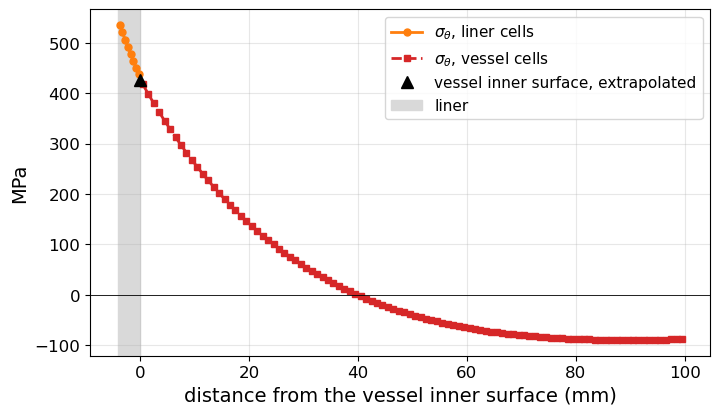

In [6]:
I_TT = 4        # z3st axisymmetric tensor order is (r, theta, z): 0 = rr, 4 = theta-theta, 8 = zz

def hoop_cells(vtu, Lz):
    """Hoop stress of one row of cells at mid-height, from the wetted surface outwards: (r of the centres, stress)."""
    g = pv.read(vtu)
    c, s = g.cell_centers().points, g['Stress (cells)'][:, I_TT]
    row = np.abs(c[:, 1] - c[np.argmin(np.abs(c[:, 1] - Lz/2)), 1]) < 1e-6
    o = np.argsort(c[row, 0])
    return c[row, 0][o], s[row][o]

def at_surface(r0, r, s):
    """The first two cells of a material, extrapolated to its surface r0."""
    return s[0] + (s[0] - s[1])*(r[0] - r0)/(r[1] - r[0])

def vessel_surface_hoop(vtu, Ri, Lz):
    """Hoop stress of the vessel at r = Ri. Returns the surface value, the first-cell value and the centre of that cell."""
    r, s = hoop_cells(vtu, Lz)
    r, s = r[r > Ri], s[r > Ri]
    return at_surface(Ri, r, s), s[0], r[0]

gm = yaml.safe_load(open(os.path.join(CASE_M, 'geometry.yaml')))
Rw, Ri, Ro, Lz = gm['inner_radius'], gm['interface_radius'], gm['outer_radius'], gm['Lz']
VTU = os.path.join(CASE_M, 'output', 'fields.vtu')
s_surf, s_cell, r_c = vessel_surface_hoop(VTU, Ri, Lz)

r_all, s_all = hoop_cells(VTU, Lz)
lin = r_all < Ri
s_wet = at_surface(Rw, r_all[lin], s_all[lin])

print(f'hoop stress, first vessel cell (centre at r = {r_c*1e3:.2f} mm):      {s_cell/1e6:7.1f} MPa')
print(f'hoop stress, vessel at its inner surface (two cells, extrapolated): {s_surf/1e6:7.1f} MPa')
print(f'hoop stress, liner at the wetted surface (two cells, extrapolated): {s_wet/1e6:7.1f} MPa')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot((r_all[lin] - Ri)*1e3, s_all[lin]/1e6, color='tab:orange', lw=2, label=r'$\sigma_\theta$, liner cells')
ax.plot((r_all[~lin] - Ri)*1e3, s_all[~lin]/1e6, color='tab:red', lw=2, label=r'$\sigma_\theta$, vessel cells')
ax.plot(0, s_surf/1e6, 'k^', ms=8, label='vessel inner surface, extrapolated')
ax.axvspan((Rw - Ri)*1e3, 0, color='0.85', label='liner')
ax.axhline(0, color='k', lw=0.6); ax.set_xlabel('distance from the vessel inner surface (mm)'); ax.set_ylabel('MPa')
ax.grid(alpha=0.3); ax.legend(); plt.show()


---
## 5. The hand estimate against Z3ST

Before believing the number, compute it by hand. The vessel alone, with no liner: the formulas of §1, with the slab profile of G4 and the source at the vessel inner surface, $q_i''' = q_0''' e^{-\mu t_L}$.

$$T(x) - T(0) = \frac{q_i'''}{k\mu^2}\Big[1 - e^{-\mu x} - \mu x\ e^{-\mu t}\Big]$$

with $x = r - R_i$, $k$ the conductivity, $\mu$ the attenuation coefficient, $t$ the vessel thickness and $t_L$ the liner thickness.

In [7]:
# --- the neutral data, read from the case rather than retyped ---------------------
mat = yaml.safe_load(open(os.path.join(CASE_M, 'steel_neutral.yaml')))
E, nu, k, alpha, mu, q0 = (mat[key] for key in ('E', 'nu', 'k', 'alpha', 'mu_gamma', 'gamma_heating'))
bc = yaml.safe_load(open(os.path.join(CASE_M, 'boundary_conditions.yaml')))['mechanical']['steel']
P = -next(b['traction'] for b in bc if b['type'] == 'Neumann' and b['region'] == 'inner_radius')

t_L, t = Ri - Rw, Ro - Ri
q_i = q0*np.exp(-mu*t_L)                     # the source at the vessel inner surface
r = np.linspace(Ri, Ro, 20001); x = r - Ri
T = q_i/(k*mu**2)*(1 - np.exp(-mu*x) - mu*x*np.exp(-mu*t))     # T(x) - T(0)
s_T = alpha*E/(1 - nu)*2/(Ro**2 - Ri**2)*np.trapezoid(T*r, r)  # the bracket of section 1, T(Ri) = 0 here
s_P = P*(Ro**2 + Ri**2)/(Ro**2 - Ri**2)

print(f'thermal stress   {s_T/1e6:7.1f} MPa')
print(f'pressure (Lame)  {s_P/1e6:7.1f} MPa')
print(f'hand estimate    {(s_T + s_P)/1e6:7.1f} MPa')
print(f'Z3ST             {s_surf/1e6:7.1f} MPa   (hand estimate {100*((s_T + s_P)/s_surf - 1):+.1f} %)')

thermal stress     402.8 MPa
pressure (Lame)     53.6 MPa
hand estimate      456.3 MPa
Z3ST               427.1 MPa   (hand estimate +6.8 %)


The hand estimate is high. Is that the mesh, or are these two different problems? The hand estimate has no liner, and the liner carries part of the hoop load. Test it by changing one number: the same case, with a liner of almost no stiffness.

In [8]:
def variant(tag, n_L=9, n_V=101, E_liner=None):
    # a copy of the neutral case with the mesh, or the stiffness of the liner, changed; returns the vessel reading
    d = os.path.join('/tmp', f'g5_{tag}')
    shutil.rmtree(d, ignore_errors=True)
    shutil.copytree(CASE_M, d, ignore=shutil.ignore_patterns('output', 'mesh.msh', 'log_*'))
    g = open(os.path.join(d, 'mesh.geo')).read()
    assert 'n_L = 9;' in g and 'n_V = 101;' in g, 'mesh.geo changed: update the two replace() strings'
    open(os.path.join(d, 'mesh.geo'), 'w').write(g.replace('n_L = 9;', f'n_L = {n_L};').replace('n_V = 101;', f'n_V = {n_V};'))
    if E_liner is not None:
        y = open(os.path.join(d, 'liner_neutral.yaml')).read()
        assert 'E: 1.95e+11' in y, 'liner_neutral.yaml changed: update the replace() string'
        open(os.path.join(d, 'liner_neutral.yaml'), 'w').write(y.replace('E: 1.95e+11', f'E: {E_liner:.2e}'))
    for cmd in (['gmsh', 'mesh.geo', '-2', '-o', 'mesh.msh'], [sys.executable, '-m', 'z3st']):
        run = subprocess.run(cmd, cwd=d, capture_output=True, text=True)
        if run.returncode != 0:
            print(run.stdout[-2000:]); print(run.stderr[-2000:])
            raise SystemExit(f'{cmd[0]} failed in {d}')
    return vessel_surface_hoop(os.path.join(d, 'output', 'fields.vtu'), Ri, Lz)

s_soft, _, _ = variant('soft_liner', E_liner=1.0e7)
print(f'hand estimate, vessel alone   {(s_T + s_P)/1e6:7.1f} MPa')
print(f'Z3ST, almost no liner         {s_soft/1e6:7.1f} MPa')
print(f'Z3ST, the real liner          {s_surf/1e6:7.1f} MPa')

hand estimate, vessel alone     456.3 MPa
Z3ST, almost no liner           450.6 MPa
Z3ST, the real liner            427.1 MPa


Without the stiffness of the liner, Z3ST comes back to within about 1 % of the hand estimate. So most of the gap is the liner: for the vessel, the estimate that ignores it reads high, on the safe side. On your vessel, do not assume the same sign: compute it.

---
## 6. Is the mesh fine enough?

> **When your FE result disagrees with your hand calculation, decide whether the disagreement is physical or numerical.**

A physical discrepancy means the two models are not the same problem, as in §5. A numerical one means the mesh is not yet fine enough. Only the second is fixed by refining the mesh, and refining is how you tell them apart: the same case, on finer and finer radial meshes. Watch the quantity your verification depends on.

In [9]:
print(f"{'n_V':>5}{'cell (mm)':>11}{'first cell (MPa)':>18}{'surface (MPa)':>15}")
for n_L, n_V in ((3, 26), (5, 51), (9, 101), (17, 201)):
    s, s1, _ = variant(f'n{n_V}', n_L, n_V)
    print(f'{n_V:5d}{(Ro - Ri)*1e3/(n_V - 1):11.1f}{s1/1e6:18.1f}{s/1e6:15.1f}')
print(f'\nthe hand estimate, on any mesh: {(s_T + s_P)/1e6:.1f} MPa')

  n_V  cell (mm)  first cell (MPa)  surface (MPa)


   26        4.0             390.4          424.8


   51        2.0             408.3          426.6


  101        1.0             417.6          427.1


  201        0.5             422.4          427.2

the hand estimate, on any mesh: 456.3 MPa


The reading at the surface moves by about 2 MPa from the coarsest mesh to the finest, and the first-cell value by over 30: **where** you read matters as much as the mesh. The gap to the hand estimate hardly moves, which is what makes it physical.

**Run the same sweep on your own case**: the knobs are `n_L` and `n_V` in `mesh.geo`, the nodes across liner and vessel.

---
## 7. Your vessel

Behind the shield, the neutral case is `cases/G5_lined_wall_shielded`: the same case, with the two numbers of G4 §8 changed, the source $q_0 e^{-\mu t_s}$ in the two cards and $h_{out}$ on the wetted surface.

1. **Put your two G4 cases back**, `my_vessel` and `my_vessel_shielded` (the cell below asks for the two zips on Colab).
2. **The material cards**: $E$, $\nu$, $\alpha$ and `T_ref` of **your** liner and vessel, in place of the neutral ones (§2).
3. **`input.yaml`** and **`boundary_conditions.yaml`**: the two changes of §2, with **your** loads. Which pressures act on your wall, and on which faces, is a decision you made in Part 0 and Part 1: write them as you decided them, and the axial load that goes with them. The same changes in **both** cases: they differ only in the source and in $h_1$ (G4 §8).
4. **The hand estimate**: the relation of item 9, with $\sigma^T$ read from the design curve (Fig. 2), on the vessel alone, with $q_0'''$ at its inner surface, with and without the attenuation of the liner, plus the pressure.
5. **Keep the mesh of G4** to start with, then converge on the hoop stress of the vessel at its inner surface (§6).
6. **Compare** the two before believing either. The self-check of your case is still the one of G4: its PASS covers the **temperature** only. The stress is checked by your hand estimate and by the convergence study, nothing else.

The vessel you verify in G6 is the vessel **of your design**: the shielded one if your design has the shield. The other one is the comparison, not a second chance.

### For your report

Your own FE case, solved without and with the shield, with the comparison against your hand estimate, a convergence study on the quantity your verification depends on, and one sentence naming any remaining discrepancy and saying whether it is physical or numerical.

### Checklist

- What is the hoop stress of your vessel at its inner surface, read where, and on what mesh?
- How do you know that mesh is fine enough?
- Where does your FE differ from your hand calculation, and is that difference physical or numerical? **How did you decide?**
- How much does the shield lower the hoop stress of your vessel, and why that much?

In [10]:
# ---- your own cases: the G4 lined wall, mechanics added, without and with the shield ----
MY_CASES = {'no shield': ndt_setup.workdir('my_vessel'),            # the same folders as in G4
            'shield':    ndt_setup.workdir('my_vessel_shielded')}
for MY_CASE in MY_CASES.values():
    print('restoring', os.path.basename(MY_CASE))
    ndt_setup.restore_work(MY_CASE)    # on Colab: upload THIS zip, the one saved in G4

# ... then make the changes of section 7 to the cards, input.yaml and boundary_conditions.yaml, in BOTH cases
# for MY_CASE in MY_CASES.values():
#     ndt_setup.run_case(MY_CASE)

restoring my_vessel
already here, nothing to restore: ~/ndt-labs/ndt-work/my_vessel
restoring my_vessel_shielded
already here, nothing to restore: ~/ndt-labs/ndt-work/my_vessel_shielded


In [11]:
# ---- your cases, solved: the hoop stress of the VESSEL at its inner surface ----------
for label, MY_CASE in MY_CASES.items():
    VTU_MY = os.path.join(MY_CASE, 'output', 'fields.vtu')
    if not os.path.isfile(VTU_MY) or 'Stress (cells)' not in pv.read(VTU_MY).array_names:
        print(f'{label:9}: no stress yet: switch the mechanics on and run it.')
        continue
    gy = yaml.safe_load(open(os.path.join(MY_CASE, 'geometry.yaml')))
    # a G4 case saved before the keys were renamed has Ri/Rm/Ro: both are read
    s, s1, r1 = vessel_surface_hoop(VTU_MY, gy.get('interface_radius', gy.get('Rm')), gy['Lz'])
    print(f'{label:9}: first vessel cell (r = {r1:.4f} m) {s1/1e6:7.1f} MPa, at its inner surface {s/1e6:7.1f} MPa')
print('the number to carry to G6: the inner surface of the vessel of YOUR design')

no shield: no stress yet: switch the mechanics on and run it.
shield   : no stress yet: switch the mechanics on and run it.
the number to carry to G6: the inner surface of the vessel of YOUR design


---
## Take your cases with you

On Colab your cases live in `/content`, which is the scratch disk of the virtual machine Colab
lent you for this notebook. **When the runtime ends it is deleted**, and G6 needs these
exact vessels. The notebook survives (it is a file), but the cases do not.

So the last action here is to download them. One cell, and the two zips are yours.
(On your own machine this does nothing: the cases are already on a real disk.)

In [12]:
for MY_CASE in MY_CASES.values():
    ndt_setup.save_work(MY_CASE)

/tmp/my_vessel.zip  (0.3 MB)
local run: your case is already on disk, nothing to download
/tmp/my_vessel_shielded.zip  (0.3 MB)
local run: your case is already on disk, nothing to download
